# SONAR · Recomendación musical basada en contenido

**Notebook autónomo para Google Colab, con el dataset en Google Drive.**

Selecciona una canción y encuentra otras similares según nueve descriptores de audio. Incluye análisis del dataset, explicación matemática, gráficos y controles interactivos.

## Antes de comenzar

1. Sube **`dataset.csv`** a una carpeta de tu Google Drive; por ejemplo, `Mi unidad/SONAR/dataset.csv`.
2. Abre este `.ipynb` en [Google Colab](https://colab.research.google.com/), mediante **Archivo → Subir notebook**.
3. Ejecuta las celdas en orden. Autoriza el montaje de tu Drive cuando Colab lo solicite.
4. En la sección **3**, cambia la ruta del CSV. Para la carpeta del ejemplo es `/content/drive/MyDrive/SONAR/dataset.csv`.
5. Continúa hasta la sección **10** para usar la interfaz.

Puedes usar **Entorno de ejecución → Ejecutar todas** después de ajustar la ruta. Una CPU es suficiente. El notebook contiene todo el código: no necesitas subir `app.py`, `recommender.py` ni la carpeta de la web.

**Alcance:** recomendación ítem a ítem basada exclusivamente en contenido. La puntuación usa atributos del audio; la popularidad, los géneros y los datos de otros usuarios no intervienen en el ranking. Los descriptores ya vienen calculados en el CSV.

## 1. Preparar las bibliotecas

La celda instala únicamente bibliotecas que falten, sin forzar cambios de versión en el entorno de Colab.

In [1]:
#@title Celda 01 · Preparar bibliotecas
import importlib.util
import subprocess
import sys

paquetes = {
    "numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn",
    "matplotlib": "matplotlib", "ipywidgets": "ipywidgets",
}
faltantes = [paquete for modulo, paquete in paquetes.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])
print("Bibliotecas disponibles.")

Bibliotecas disponibles.


In [2]:
#@title Celda 02 · Importar bibliotecas
from pathlib import Path
from html import escape
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
from sklearn.metrics.pairwise import cosine_similarity

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass  # También permite ejecutar el notebook en Jupyter.

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
VERDE, VIOLETA = "#659b27", "#8862bd"
print(f"Python {sys.version.split()[0]} · NumPy {np.__version__} · pandas {pd.__version__}")

Python 3.11.2 · NumPy 2.4.4 · pandas 3.0.2


## 2. Conectar Google Drive

La autorización se realiza dentro de Colab. El montaje permite leer el CSV desde tu Drive; este notebook no modifica el archivo original.

In [3]:
print("Validación local: se usa archive/dataset.csv; no se monta Google Drive.")

Validación local: se usa archive/dataset.csv; no se monta Google Drive.


## 3. Indicar la ruta del CSV

Edita `RUTA_DATASET`. Si subiste el archivo directamente a **Mi unidad**, usa `/content/drive/MyDrive/dataset.csv`. Si lo guardaste en una carpeta, incluye su nombre. Usa el panel **Archivos** de Colab para localizarlo y **Copiar ruta** si lo necesitas.

La ruta distingue mayúsculas y minúsculas. Debe apuntar al archivo `.csv` descomprimido.

**Si aparece `dataset_pseudo.csv` o columnas como `comentario_original`, `emocion_score` y `pseudo_label`:** estás leyendo otro dataset. Sustituye la ruta por la del CSV de canciones de Spotify y vuelve a ejecutar desde esta sección. Cambiar solamente el nombre del archivo de comentarios no agrega los atributos de audio que faltan.


In [4]:
#@title Celda 04 · Definir ruta del CSV
RUTA_DATASET = '/home/aldair/Documentos/X SEMESTRE/RECOMENdACION/tarea_uniaa/archive/dataset.csv' #@param {type:"string"}
DATASET_PATH = Path(RUTA_DATASET)
if not DATASET_PATH.is_file():
    raise FileNotFoundError(
        f"No se encontró el CSV: {DATASET_PATH}\n"
        "Monta Drive, copia la ruta real del archivo y modifica RUTA_DATASET."
    )
if DATASET_PATH.suffix.lower() != ".csv":
    raise ValueError("Selecciona dataset.csv, no el archivo ZIP.")
print(f"CSV encontrado · {DATASET_PATH.stat().st_size / 1_000_000:.2f} MB")

CSV encontrado · 20.15 MB


## 4. Explorar la base de datos

Cada fila es un registro de una canción asociado a una etiqueta de género. `track_id` identifica la pista y puede aparecer en varias filas.

El archivo usado para desarrollar el proyecto tiene **114 000 filas, 21 columnas y 114 etiquetas de género**. La celda calcula los conteos de tu archivo; no los supone de antemano.

**Celda de código 05:** muestra la lista completa de columnas y la tabla de las nueve características. Detecta archivos separados por coma, punto y coma o tabulación, y normaliza espacios y mayúsculas de los encabezados. Si falta algún atributo obligatorio, muestra qué columnas encontró y cuáles faltan.


In [5]:
#@title Celda 05 · Leer CSV y verificar columnas
import csv
import re
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

FEATURES = {
    "danceability": "Bailabilidad", "energy": "Energía", "valence": "Valencia",
    "acousticness": "Acústica", "instrumentalness": "Instrumentalidad",
    "speechiness": "Voz hablada", "liveness": "Presencia de público",
    "tempo": "Tempo", "loudness": "Sonoridad",
}
COLUMNAS_REQUERIDAS = ["track_id", "track_name", "artists", "track_genre", *FEATURES]
COLUMNAS_ORIGINALES = [
    "track_id", "artists", "album_name", "track_name", "popularity", "duration_ms",
    "explicit", "danceability", "energy", "key", "loudness", "mode", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence", "tempo",
    "time_signature", "track_genre",
]

def cargar_dataset(ruta):
    """Detecta el separador, normaliza encabezados y valida el esquema de audio."""
    ruta = Path(ruta)
    if not ruta.is_file():
        raise FileNotFoundError(f"No se encontró {ruta}. Revisa la ruta en la celda 4.")
    with ruta.open("r", encoding="utf-8-sig", newline="") as archivo:
        encabezado = archivo.readline()
    try:
        separador = csv.Sniffer().sniff(encabezado, delimiters=",;\t|").delimiter
    except csv.Error:
        separador = ","
    datos = pd.read_csv(ruta, sep=separador, encoding="utf-8-sig")
    originales = list(datos.columns)
    normalizadas = [re.sub(r"\s+", "_", str(c).replace("\ufeff", "").strip().lower())
                    for c in originales]
    if len(set(normalizadas)) != len(normalizadas):
        raise ValueError("Los encabezados quedan repetidos al normalizarlos. Revisa el CSV.")
    datos.columns = normalizadas
    faltantes = [c for c in COLUMNAS_REQUERIDAS if c not in datos.columns]
    if faltantes:
        columnas_texto = {"comentario_original", "emocion_score", "pseudo_label"}
        contexto = (
            "Se reconocen columnas de comentarios o análisis de emociones. "
            "Este archivo corresponde a otro conjunto de datos.\n"
            if columnas_texto.intersection(datos.columns) else ""
        )
        raise ValueError(
            f"Archivo leído: {ruta}\n"
            + contexto
            + "El CSV no contiene las columnas necesarias para este recomendador.\n"
            f"Separador detectado: {repr(separador)}\n"
            f"Columnas detectadas ({len(datos.columns)}): {list(datos.columns)}\n"
            f"Columnas requeridas que faltan: {faltantes}\n"
            "Comprueba que la ruta apunte al Spotify Tracks Dataset con características "
            "de audio y no a un CSV de playlists, valoraciones o metadatos diferentes. "
            "No se inventan atributos ni se rellenan columnas ausentes."
        )
    return datos, separador, originales

if "DATASET_PATH" not in globals():
    raise RuntimeError("Primero ejecuta las celdas 3 y 4 para montar Drive y definir la ruta.")
df_original = None
globals().pop("modelo", None)
df_original, separador_csv, encabezados_originales = cargar_dataset(DATASET_PATH)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 70)
print(f"Archivo leído: {DATASET_PATH}")
print(f"Filas: {len(df_original):,} · Columnas: {df_original.shape[1]} · Separador: {repr(separador_csv)}")
print("Columnas encontradas:", df_original.columns.tolist())
print("\nPrimeras filas (encabezados completos):")
display(df_original.head(3))
diccionario = pd.DataFrame({
    "Columna": df_original.columns,
    "Tipo": [str(tipo) for tipo in df_original.dtypes],
    "Faltantes": df_original.isna().sum().to_numpy(),
    "Valores distintos": df_original.nunique().to_numpy(),
    "Uso en el ranking": ["Sí: atributo de audio" if c in FEATURES else "No"
                           for c in df_original.columns],
})
display(diccionario)
print("\nLas nueve características de audio:")
display(df_original[list(FEATURES)].head())
print(f"Identificadores distintos: {df_original.track_id.nunique():,}")
conteo_generos = df_original.track_genre.value_counts()
print(f"Etiquetas de género: {len(conteo_generos)}")
if not conteo_generos.empty:
    print(f"Filas por etiqueta: mínimo {conteo_generos.min():,}, máximo {conteo_generos.max():,}")
print("\nEsquema verificado. Continúa con la celda 6.")

Archivo leído: /home/aldair/Documentos/X SEMESTRE/RECOMENdACION/tarea_uniaa/archive/dataset.csv
Filas: 114,000 · Columnas: 21 · Separador: ','
Columnas encontradas: ['unnamed:_0', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']

Primeras filas (encabezados completos):


,unnamed:_0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.461,1,-6.746,0,0.1430,0.0322,0.000001,0.358,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.166,1,-17.235,1,0.0763,0.9240,0.000006,0.101,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.359,0,-9.734,1,0.0557,0.2100,0.000000,0.117,0.120,76.332,4,acoustic


,Columna,Tipo,Faltantes,Valores distintos,Uso en el ranking
0,unnamed:_0,int64,0,114000,No
1,track_id,str,0,89741,No
2,artists,str,1,31437,No
3,album_name,str,1,46579,No
4,track_name,str,1,73604,No
5,popularity,int64,0,101,No
6,duration_ms,int64,0,50697,No
7,explicit,bool,0,2,No
8,danceability,float64,0,1174,Sí: atributo de audio
9,energy,float64,0,2083,Sí: atributo de audio



Las nueve características de audio:


,danceability,energy,valence,acousticness,instrumentalness,speechiness,liveness,tempo,loudness
0,0.676,0.4610,0.715,0.0322,0.000001,0.1430,0.3580,87.917,-6.746
1,0.420,0.1660,0.267,0.9240,0.000006,0.0763,0.1010,77.489,-17.235
2,0.438,0.3590,0.120,0.2100,0.000000,0.0557,0.1170,76.332,-9.734
3,0.266,0.0596,0.143,0.9050,0.000071,0.0363,0.1320,181.740,-18.515
4,0.618,0.4430,0.167,0.4690,0.000000,0.0526,0.0829,119.949,-9.681


Identificadores distintos: 89,741
Etiquetas de género: 114
Filas por etiqueta: mínimo 1,000, máximo 1,000

Esquema verificado. Continúa con la celda 6.


### Qué columnas se utilizan

| Grupo | Columnas | Función |
| --- | --- | --- |
| Identidad y búsqueda | `track_id`, `track_name`, `artists` | Seleccionar canciones, mostrarlas y evitar repeticiones |
| Metadatos | `album_name`, `track_genre` | Contexto descriptivo; género se agrupa por ID |
| Audio: atributos de 0 a 1 | `danceability`, `energy`, `valence`, `acousticness`, `instrumentalness`, `speechiness`, `liveness` | Características del modelo |
| Audio: otras unidades | `tempo` en BPM y `loudness` en dB | Características del modelo |
| Columnas no seleccionadas | `popularity`, `duration_ms`, `explicit`, `key`, `mode`, `time_signature`, `Unnamed: 0` | No intervienen en la puntuación |

Las etiquetas de género incluyen categorías de estilo, región o contexto; su distribución en este CSV no representa necesariamente la distribución real de consumo musical. El archivo no contiene interacciones de usuarios ni etiquetas de relevancia. La fecha, licencia y procedencia deben verificarse en la ficha original de descarga.

## 5. Construir el recomendador

Se descartan registros sin ID, título o artista; se conserva una fila por ID y se reúnen sus géneros. Los atributos ausentes o no finitos se completan con la mediana; si una característica no tiene ningún valor válido, se detiene el proceso.

Se estandariza cada atributo sobre el catálogo limpio:

$$z_j = \frac{x_j - \mu_j}{\sigma_j}$$

Con pesos $w_j$ entre 0 y 3, el vector utilizado es $v_j = \sqrt{w_j}z_j$. La similitud es:

$$\operatorname{cos}(a,b) = \frac{\sum_j w_j z_{aj}z_{bj}}{\sqrt{\sum_j w_j z_{aj}^2}\sqrt{\sum_j w_j z_{bj}^2}}$$

El coseno está entre −1 y 1; mide alineación de vectores y no una probabilidad de gusto. El uso de la raíz hace que el producto escalar incorpore $w_j$ y no $w_j^2$.

**Celda de código 06:** define el recomendador y muestra sus nueve columnas. **Celda 07:** prepara el catálogo a partir del mismo DataFrame validado en la celda 05, sin volver a leer el CSV con una configuración distinta.


In [6]:
#@title Celda 06 · Definir el recomendador
"""Recomendación ítem a ítem usando exclusivamente características del audio."""
from pathlib import Path
import unicodedata

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

if "FEATURES" not in globals() or not isinstance(globals().get("df_original"), pd.DataFrame):
    raise RuntimeError("Ejecuta primero la celda 5 y verifica que indique «Esquema verificado».")



def normalized_text(value):
    """Normaliza texto para búsqueda y para excluir versiones con el mismo título."""
    return "".join(c for c in unicodedata.normalize("NFKD", str(value).casefold())
                   if not unicodedata.combining(c)).strip()


class ContentRecommender:
    def __init__(self, data=None):
        if data is None:
            data = globals().get("df_original")
        if isinstance(data, pd.DataFrame):
            source = data.copy()
        elif data is not None:
            source, _, _ = cargar_dataset(data)
        else:
            raise RuntimeError("Ejecuta primero la celda 5 para cargar y verificar el CSV.")
        required = {"track_id", "track_name", "artists", "track_genre", *FEATURES}
        missing = required - set(source.columns)
        if missing:
            raise ValueError(f"Faltan columnas: {', '.join(sorted(missing))}")
        valid = source.dropna(subset=["track_id", "track_name", "artists"]).copy()
        for column in ["track_id", "track_name", "artists"]:
            valid = valid[valid[column].astype(str).str.strip().ne("")]
        genres = valid.groupby("track_id", sort=False).track_genre.agg(
            lambda values: sorted(set(values.dropna().astype(str))))
        self.frame = valid.drop_duplicates("track_id", keep="first").reset_index(drop=True)
        self.frame["genres"] = self.frame.track_id.map(genres)
        values = self.frame[list(FEATURES)].apply(pd.to_numeric, errors="coerce")
        values = values.replace([np.inf, -np.inf], np.nan)
        imputed = int(values.isna().sum().sum())
        # Una columna completamente ausente no permite un escalado interpretable.
        if values.isna().all().any():
            raise ValueError("Hay características sin ningún valor numérico válido.")
        self.raw = values.fillna(values.median()).to_numpy(dtype=float)
        if len(self.raw) < 2:
            raise ValueError("Se necesitan al menos dos canciones válidas.")
        self.scaler = StandardScaler()
        self.vectors = self.scaler.fit_transform(self.raw)
        self.ids = {str(value): i for i, value in enumerate(self.frame.track_id)}
        self.search_text = (self.frame.track_name + " " + self.frame.artists).map(normalized_text)
        self.signatures = (self.frame.track_name.map(normalized_text) + "|" +
                           self.frame.artists.map(normalized_text)).to_numpy()
        self.stats = {
            "rows": len(source), "tracks": len(self.frame),
            "invalid_rows": len(source) - len(valid),
            "duplicate_ids": len(valid) - len(self.frame),
            "genres": int(valid.track_genre.nunique()), "imputed_values": imputed,
            "features": [{"key": key, "label": label,
                          "mean": float(self.scaler.mean_[j]),
                          "std": float(self.scaler.scale_[j])}
                         for j, (key, label) in enumerate(FEATURES.items())],
        }

    def track(self, index):
        row = self.frame.iloc[index]
        return {"id": str(row.track_id), "name": str(row.track_name),
                "artists": str(row.artists), "genres": row.genres,
                "values": dict(zip(FEATURES, self.raw[index].tolist()))}

    def search(self, query, limit=20):
        query = normalized_text(query)
        if not query:
            return []
        mask = self.search_text.str.contains(query, regex=False)
        indices = np.flatnonzero(mask.to_numpy())
        # Coincidencias exactas primero; nunca ordenar por popularidad.
        indices = sorted(indices, key=lambda i: (
            normalized_text(self.frame.iloc[i].track_name) != query, i))
        return [self.track(i) for i in indices[:limit]]

    def recommend(self, track_id, count=6, weights=None):
        if track_id not in self.ids:
            raise KeyError("Canción no encontrada.")
        if not 1 <= count <= 20:
            raise ValueError("La cantidad debe estar entre 1 y 20.")
        weights = weights if weights is not None else {}
        if not isinstance(weights, dict) or set(weights) - set(FEATURES):
            raise ValueError("Los pesos deben corresponder a las características disponibles.")
        w = np.array([float(weights.get(key, 1)) for key in FEATURES])
        if not np.isfinite(w).all() or (w < 0).any() or (w > 3).any() or not w.any():
            raise ValueError("Usa pesos de 0 a 3 y activa al menos una característica.")
        index = self.ids[track_id]
        # sqrt(w) hace que el producto escalar use w, no w².
        weighted = self.vectors * np.sqrt(w)
        norms = np.linalg.norm(weighted, axis=1)
        if norms[index] < 1e-12:
            raise ValueError("La canción tiene un vector nulo con estos pesos. Activa otra característica.")
        unit = np.divide(weighted, norms[:, None], out=np.zeros_like(weighted),
                         where=norms[:, None] > 1e-12)
        scores = np.clip(unit @ unit[index], -1, 1)
        eligible = (norms > 1e-12) & (self.signatures != self.signatures[index])
        ranked = np.argsort(-np.where(eligible, scores, -np.inf), kind="stable")
        seen = {self.signatures[index]}
        recommendations = []
        for candidate in ranked:
            if not eligible[candidate] or self.signatures[candidate] in seen:
                continue
            seen.add(self.signatures[candidate])
            explanation = []
            for j, (key, label) in enumerate(FEATURES.items()):
                explanation.append({"key": key, "label": label, "weight": float(w[j]),
                    "seed_raw": float(self.raw[index, j]), "candidate_raw": float(self.raw[candidate, j]),
                    "seed_z": float(self.vectors[index, j]), "candidate_z": float(self.vectors[candidate, j]),
                    "contribution": float(unit[index, j] * unit[candidate, j]),
                    "distance_z": float(abs(self.vectors[index, j] - self.vectors[candidate, j]))})
            closest = sorted((item for item in explanation if item["weight"] > 0),
                             key=lambda item: item["distance_z"])[:3]
            recommendations.append({**self.track(candidate), "score": float(scores[candidate]),
                                    "explanation": explanation, "closest": [x["label"] for x in closest]})
            if len(recommendations) == count:
                break
        return {"seed": self.track(index), "recommendations": recommendations,
                "weights": dict(zip(FEATURES, w.tolist())),
                "compared": int(eligible.sum())}

print("Recomendador definido. Estas son las columnas utilizadas:")
display(pd.DataFrame({"Columna de audio": list(FEATURES), "Significado": list(FEATURES.values())}))
print("Continúa con la celda 7 para preparar el catálogo limpio.")

Recomendador definido. Estas son las columnas utilizadas:


,Columna de audio,Significado
0,danceability,Bailabilidad
1,energy,Energía
2,valence,Valencia
3,acousticness,Acústica
4,instrumentalness,Instrumentalidad
5,speechiness,Voz hablada
6,liveness,Presencia de público
7,tempo,Tempo
8,loudness,Sonoridad


Continúa con la celda 7 para preparar el catálogo limpio.


In [7]:
#@title Celda 07 · Preparar catálogo limpio
if not isinstance(globals().get("df_original"), pd.DataFrame):
    raise RuntimeError("Ejecuta primero la celda 5 para cargar el CSV y luego la 6.")
modelo = ContentRecommender(df_original)
resumen = pd.DataFrame([
    ("Filas originales", modelo.stats["rows"]),
    ("Filas sin identidad, título o artista", modelo.stats["invalid_rows"]),
    ("Repeticiones adicionales de ID", modelo.stats["duplicate_ids"]),
    ("Canciones únicas válidas", modelo.stats["tracks"]),
    ("Etiquetas de género", modelo.stats["genres"]),
    ("Valores numéricos imputados", modelo.stats["imputed_values"]),
], columns=["Medida", "Cantidad"])
display(resumen)
print("Modelo preparado: nueve atributos de audio, pesos iniciales iguales a 1.")

,Medida,Cantidad
0,Filas originales,114000
1,"Filas sin identidad, título o artista",1
2,Repeticiones adicionales de ID,24259
3,Canciones únicas válidas,89740
4,Etiquetas de género,114
5,Valores numéricos imputados,0


Modelo preparado: nueve atributos de audio, pesos iniciales iguales a 1.


## 6. Inspeccionar los atributos y sus escalas

Las estadísticas corresponden al catálogo limpio. Tempo y sonoridad tienen unidades diferentes de los siete descriptores de 0 a 1; por eso se estandarizan antes de calcular la similitud. StandardScaler es sensible a valores extremos; en este proyecto no se aplica un filtro de outliers.

Columnas del modelo: ['danceability', 'energy', 'valence', 'acousticness', 'instrumentalness', 'speechiness', 'liveness', 'tempo', 'loudness']


,Mínimo,Media,Mediana,Máximo
danceability,0.000,0.5622,0.5760,0.985
energy,0.000,0.6345,0.6760,1.000
valence,0.000,0.4695,0.4570,0.995
acousticness,0.000,0.3283,0.1880,0.996
instrumentalness,0.000,0.1734,0.0001,1.000
speechiness,0.000,0.0874,0.0489,0.965
liveness,0.000,0.2170,0.1320,1.000
tempo,0.000,122.0581,122.0130,243.372
loudness,-49.531,-8.4990,-7.1850,4.532


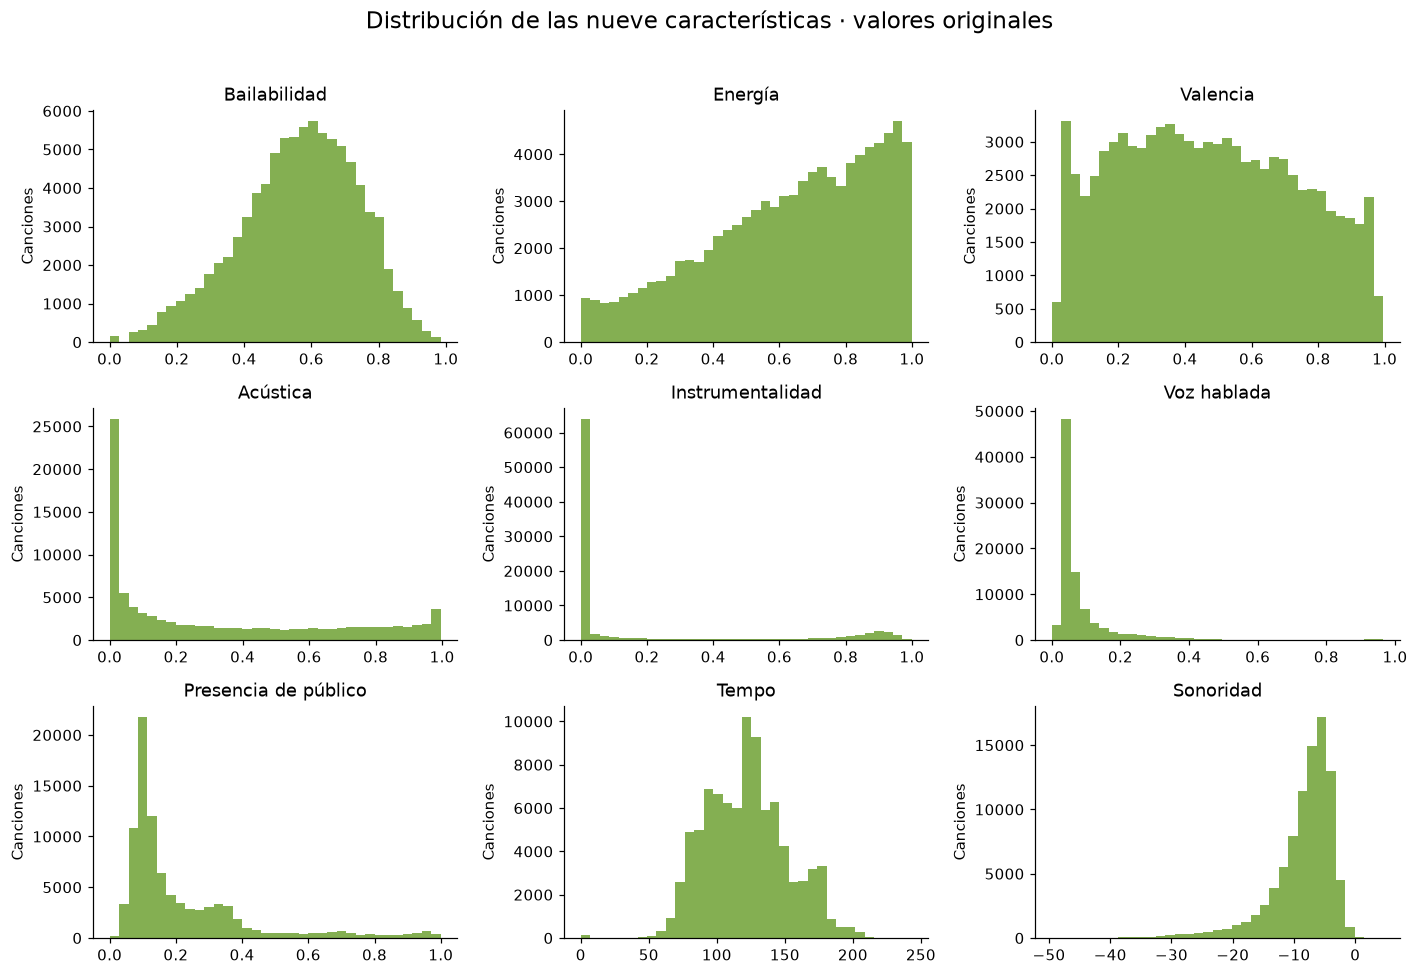

,danceability,energy,valence,acousticness,instrumentalness,speechiness,liveness,tempo,loudness
0,0.644,-0.676,0.934,-0.875,-0.535,0.490,0.724,-1.134,0.336
1,-0.805,-1.826,-0.770,1.761,-0.535,-0.098,-0.595,-1.480,-1.673
2,-0.703,-1.073,-1.329,-0.350,-0.535,-0.280,-0.513,-1.518,-0.237


In [8]:
#@title Celda 08 · Inspeccionar atributos y escalas
if "modelo" not in globals():
    raise RuntimeError("Ejecuta primero las celdas 5, 6 y 7, en ese orden.")
print("Columnas del modelo:", list(FEATURES))
atributos = pd.DataFrame(modelo.raw, columns=list(FEATURES))
display(atributos.describe().T[["min", "mean", "50%", "max"]].rename(
    columns={"min": "Mínimo", "mean": "Media", "50%": "Mediana", "max": "Máximo"}
).round(4))
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, (key, label) in zip(axes.flat, FEATURES.items()):
    ax.hist(atributos[key], bins=35, color=VERDE, alpha=.8)
    ax.set_title(label)
    ax.set_ylabel("Canciones")
fig.suptitle("Distribución de las nueve características · valores originales", fontsize=15)
fig.tight_layout(rect=(0, 0, 1, .96))
plt.show()
plt.close(fig)

# Ver el cambio de escala en las primeras tres canciones.
display(pd.DataFrame(modelo.vectors[:3], columns=list(FEATURES)).round(3))

## 7. Ejecutar un ejemplo reproducible

Se usa **Blinding Lights**, de **The Weeknd**, si existe en el CSV; en caso contrario se toma la primera canción válida y se informa su nombre. Puedes cambiar la selección más adelante en la interfaz.

La referencia se excluye del resultado. También se evitan combinaciones repetidas de título y artista normalizados; esto no elimina todas las posibles versiones o remixes.

In [9]:
#@title Celda 09 · Ejecutar ejemplo
coincidencias = modelo.search("Blinding Lights", limit=100)
ejemplo = next((t for t in coincidencias if t["artists"] == "The Weeknd"), None)
if ejemplo is None:
    ejemplo = modelo.track(0)
    print("La canción del ejemplo no está disponible; se utiliza la primera pista válida.")
resultado_ejemplo = modelo.recommend(ejemplo["id"], count=6)
print(f"Referencia: {ejemplo['name']} — {ejemplo['artists']}")
print(f"Candidatos válidos comparados: {resultado_ejemplo['compared']:,}")

def tabla_resultados(resultado):
    return pd.DataFrame([
        {"Posición": i + 1, "Canción": pista["name"], "Artistas": pista["artists"],
         "Géneros": ", ".join(pista["genres"]), "Coseno": pista["score"],
         "Cercanía descriptiva": ", ".join(pista["closest"])}
        for i, pista in enumerate(resultado["recommendations"])
    ])

display(tabla_resultados(resultado_ejemplo).round({"Coseno": 6}))

Referencia: Blinding Lights — The Weeknd
Candidatos válidos comparados: 89,735


,Posición,Canción,Artistas,Géneros,Coseno,Cercanía descriptiva
0,1,平凡人的自傳 - Rap Version,ONE PROMISE,cantopop,0.992188,"Instrumentalidad, Voz hablada, Bailabilidad"
1,2,Viah,Jass Manak,hip-hop,0.992092,"Instrumentalidad, Acústica, Tempo"
2,3,Thinkin About,ShockOne;Lee Mvtthews,"drum-and-bass, j-dance",0.988842,"Instrumentalidad, Valencia, Acústica"
3,4,Fool Yourself,Chase & Status;Plan B;Rage,drum-and-bass,0.987508,"Instrumentalidad, Acústica, Sonoridad"
4,5,30/90,Andrew Garfield;Joshua Henry;Vanessa Hudgens;Robin de Jesus;Alexan...,show-tunes,0.987308,"Instrumentalidad, Sonoridad, Acústica"
5,6,BODY,LICK;LUNA AURA,club,0.987200,"Instrumentalidad, Tempo, Acústica"


## 8. Visualizar y explicar una recomendación

El radar usa siete atributos con escala original de 0 a 1. Las barras de diferencias y la tabla incluyen los nueve atributos. La cercanía descriptiva selecciona los atributos activos con menor diferencia absoluta de valores z; no es la fórmula del ranking.

La tabla descompone exactamente el coseno. Los aportes positivos indican componentes estandarizados del mismo signo; no implican por sí solos que los valores originales sean cercanos. La suma de aportes coincide con la similitud, salvo redondeo visual.

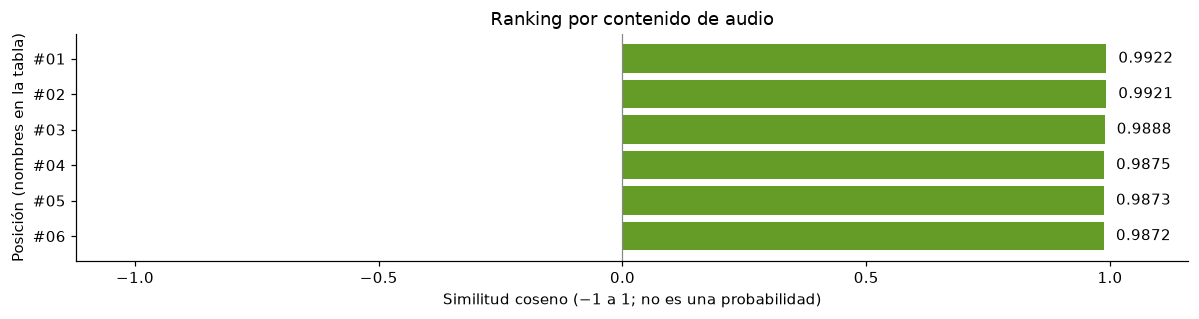

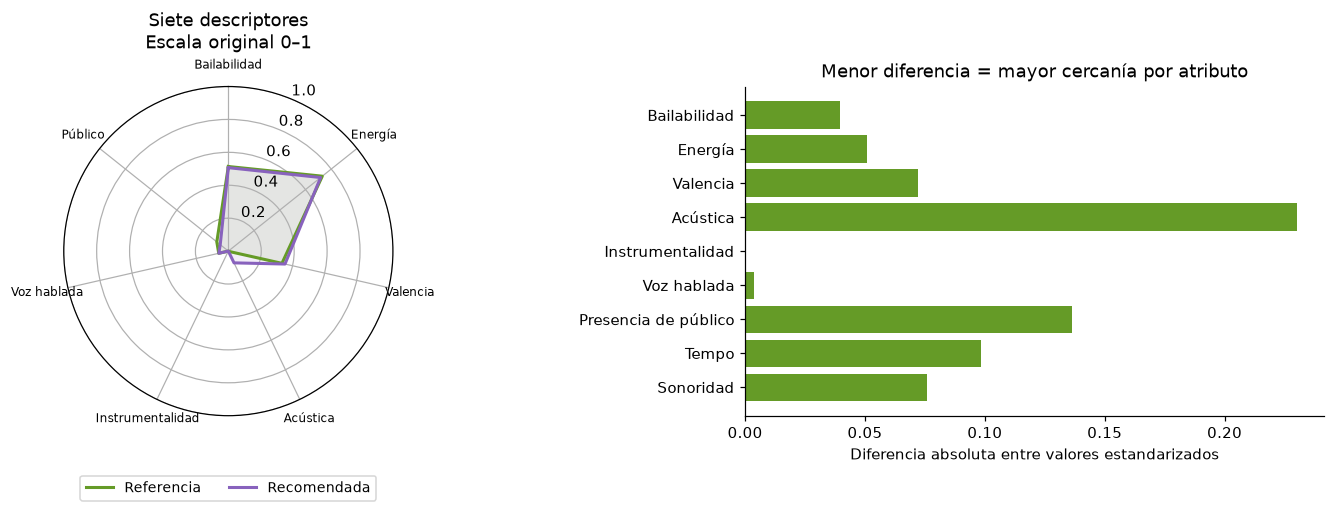

Gris: atributo con peso cero. Las diferencias son descriptivas; el ranking usa coseno ponderado.


,Característica,Base original,Recomendada original,z base,z recomendada,Peso,Aporte al coseno
0,Bailabilidad,0.514000,0.5070,-0.272602,-0.312219,1.0,0.017998
1,Energía,0.730000,0.7170,0.372329,0.321668,1.0,0.025326
2,Valencia,0.334000,0.3530,-0.515382,-0.443101,1.0,0.048291
3,Acústica,0.001460,0.0793,-0.966027,-0.735948,1.0,0.150338
4,Instrumentalidad,0.000095,0.0000,-0.535190,-0.535485,1.0,0.060602
5,Voz hablada,0.059800,0.0594,-0.244024,-0.247555,1.0,0.012774
6,Presencia de público,0.089700,0.0631,-0.653061,-0.789553,1.0,0.109035
7,Tempo,171.005000,168.0400,1.625198,1.526750,1.0,0.524693
8,Sonoridad,-5.934000,-6.3310,0.491238,0.415206,1.0,0.043131


Suma de aportes: 0.99218773 · Coseno: 0.99218773


In [10]:
#@title Celda 10 · Dibujar y explicar resultados
def dibujar_ranking(resultado):
    pistas = resultado["recommendations"]
    if not pistas:
        print("No hay recomendaciones válidas para esta configuración.")
        return
    etiquetas = [f"#{i + 1:02d}" for i, t in enumerate(pistas)]
    valores = [t["score"] for t in pistas]
    fig, ax = plt.subplots(figsize=(11, max(3, .45 * len(pistas))))
    ax.barh(etiquetas, valores, color=VERDE)
    ax.invert_yaxis()
    ax.set_xlim(-1.12, 1.16)
    ax.axvline(0, color="#888888", linewidth=.8)
    for y, valor in enumerate(valores):
        ax.text(valor + .025 if valor >= 0 else valor - .025, y,
                f"{valor:.4f}", va="center", ha="left" if valor >= 0 else "right")
    ax.set_ylabel("Posición (nombres en la tabla)")
    ax.set_xlabel("Similitud coseno (−1 a 1; no es una probabilidad)")
    ax.set_title("Ranking por contenido de audio")
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def dibujar_comparacion(resultado, indice=0):
    pistas = resultado["recommendations"]
    if not pistas:
        print("No hay una recomendación que comparar.")
        return
    base, candidata = resultado["seed"], pistas[indice]
    detalles = pd.DataFrame(candidata["explanation"])
    display(HTML(f"<h3>{escape(base['name'])} → {escape(candidata['name'])}</h3>"
                 f"<p>Coseno: <b>{candidata['score']:.6f}</b> · "
                 f"Cercanía descriptiva en: {escape(', '.join(candidata['closest']))}</p>"))
    claves = list(FEATURES)[:7]
    etiquetas = [FEATURES[k].replace("Presencia de público", "Público") for k in claves]
    angulos = np.linspace(0, 2 * np.pi, len(claves), endpoint=False)
    angulos_cerrados = np.r_[angulos, angulos[0]]
    fig = plt.figure(figsize=(13, 5))
    radar = fig.add_subplot(121, projection="polar")
    radar.set_theta_offset(np.pi / 2)
    radar.set_theta_direction(-1)
    for pista, color, nombre in [(base, VERDE, "Referencia"), (candidata, VIOLETA, "Recomendada")]:
        valores = [pista["values"][k] for k in claves]
        valores = np.r_[valores, valores[0]]
        radar.plot(angulos_cerrados, valores, color=color, label=nombre, linewidth=2)
        radar.fill(angulos_cerrados, valores, color=color, alpha=.10)
    radar.set_xticks(angulos, etiquetas, fontsize=8)
    radar.set_ylim(0, 1)
    radar.set_title("Siete descriptores\nEscala original 0–1", pad=25)
    radar.legend(loc="lower center", bbox_to_anchor=(.5, -.28), ncol=2, fontsize=9)
    diferencias = fig.add_subplot(122)
    colores = [VERDE if peso > 0 else "#bcbcbc" for peso in detalles.weight]
    diferencias.barh(detalles.label, detalles.distance_z, color=colores)
    diferencias.invert_yaxis()
    diferencias.set_xlabel("Diferencia absoluta entre valores estandarizados")
    diferencias.set_title("Menor diferencia = mayor cercanía por atributo")
    fig.tight_layout(w_pad=4)
    plt.show()
    plt.close(fig)
    print("Gris: atributo con peso cero. Las diferencias son descriptivas; el ranking usa coseno ponderado.")
    tabla = detalles[["label", "seed_raw", "candidate_raw", "seed_z", "candidate_z", "weight", "contribution"]].copy()
    tabla.columns = ["Característica", "Base original", "Recomendada original", "z base", "z recomendada", "Peso", "Aporte al coseno"]
    display(tabla.round(6))
    print(f"Suma de aportes: {detalles.contribution.sum():.8f} · Coseno: {candidata['score']:.8f}")
    assert np.isclose(detalles.contribution.sum(), candidata["score"], atol=1e-12)


dibujar_ranking(resultado_ejemplo)
dibujar_comparacion(resultado_ejemplo)

## 9. Comprobar el cálculo matemático

Las comprobaciones comparan el cálculo propio con `cosine_similarity` de scikit-learn, con y sin pesos. También verifican el primer puesto, la exclusión de la referencia, la suma de aportes y el rechazo de pesos completamente nulos. Estas pruebas validan la implementación; no miden satisfacción ni accuracy de recomendaciones.

In [11]:
#@title Celda 11 · Verificar cálculo matemático
for pesos_prueba in [None, {k: float(i % 3) for i, k in enumerate(FEATURES)}]:
    r = modelo.recommend(ejemplo["id"], count=6, weights=pesos_prueba)
    w = np.array([r["weights"][k] for k in FEATURES])
    matriz = modelo.vectors * np.sqrt(w)
    i_base = modelo.ids[ejemplo["id"]]
    referencia = cosine_similarity(matriz[i_base:i_base + 1], matriz)[0]
    validos = ((np.linalg.norm(matriz, axis=1) > 1e-12) &
               (modelo.signatures != modelo.signatures[i_base]))
    if r["recommendations"]:
        assert np.isclose(r["recommendations"][0]["score"], referencia[validos].max())
    firmas = set()
    for t in r["recommendations"]:
        i = modelo.ids[t["id"]]
        assert t["id"] != ejemplo["id"]
        assert modelo.signatures[i] not in firmas
        firmas.add(modelo.signatures[i])
        assert np.isclose(t["score"], referencia[i], atol=1e-12)
        assert np.isclose(t["score"], sum(f["contribution"] for f in t["explanation"]), atol=1e-12)
try:
    modelo.recommend(ejemplo["id"], weights={k: 0 for k in FEATURES})
except ValueError:
    pass
else:
    raise AssertionError("Debían rechazarse los pesos completamente nulos.")
assert {"popularity", "artists", "track_genre"}.isdisjoint(FEATURES)
print("Comprobaciones superadas: coseno, ranking, pesos, aportes y exclusión de duplicados.")

Comprobaciones superadas: coseno, ranking, pesos, aportes y exclusión de duplicados.


## 10. Interfaz interactiva para exponer

1. Escribe un título o artista y pulsa **Buscar**.
2. Selecciona la canción en **Referencia**.
3. Define la cantidad de recomendaciones y, si deseas, abre **Pesos de las características**.
4. Pulsa **Recomendar** para aplicar la selección y los pesos.
5. Selecciona un resultado en **Comparar** para ver sus gráficos y aportes.

**1** es el peso inicial, **0** ignora un atributo y **3** triplica su peso en la fórmula. Tras modificar la referencia, cantidad o pesos, pulsa **Recomendar**; los resultados anteriores se ocultan para evitar confundir configuraciones.

Si los controles no aparecen, vuelve a ejecutar las secciones 1 y 10. Las secciones 7 y 8 permiten presentar la demostración con tablas y gráficos incluso sin usar los controles.

In [12]:
#@title Celda 12 · Abrir interfaz interactiva
# Cerrar la interfaz anterior si vuelves a ejecutar esta celda.
if "interfaz_sonar" in globals():
    interfaz_sonar.close()

busqueda = widgets.Text(value="Blinding Lights", description="Buscar:",
    placeholder="Título o artista", layout=widgets.Layout(width="65%"))
boton_buscar = widgets.Button(description="Buscar", icon="search")
selector = widgets.Dropdown(description="Referencia:", options=[
    (f"{ejemplo['name']} — {ejemplo['artists']}", ejemplo["id"])],
    layout=widgets.Layout(width="98%"), style={"description_width": "90px"})
cantidad = widgets.Dropdown(description="Cantidad:", options=[4, 6, 10, 20], value=6)
boton_recomendar = widgets.Button(description="Recomendar", icon="music", button_style="success")
boton_restablecer = widgets.Button(description="Restablecer pesos", icon="undo")
selector_comparacion = widgets.Dropdown(description="Comparar:", options=[], disabled=True,
    layout=widgets.Layout(width="98%"), style={"description_width": "90px"})
sliders = {key: widgets.FloatSlider(value=1, min=0, max=3, step=.1, description=label,
    readout_format=".1f", continuous_update=False,
    style={"description_width": "145px"}, layout=widgets.Layout(width="95%"))
    for key, label in FEATURES.items()}
panel_pesos = widgets.Accordion(children=[widgets.VBox(list(sliders.values()) + [boton_restablecer])])
panel_pesos.set_title(0, "Pesos de las características")
panel_pesos.selected_index = None
mensaje = widgets.HTML()
salida_ranking, salida_comparacion = widgets.Output(), widgets.Output()
estado_ui = {"resultado": None, "actualizando": False}


def avisar(texto, error=False):
    color = "#a82929" if error else "#426324"
    mensaje.value = f"<p style='color:{color}'>{escape(texto)}</p>"


def invalidar(change=None):
    if estado_ui["actualizando"]:
        return
    estado_ui["resultado"] = None
    estado_ui["actualizando"] = True
    try:
        selector_comparacion.options = []
        selector_comparacion.disabled = True
    finally:
        estado_ui["actualizando"] = False
    salida_ranking.clear_output(wait=False)
    salida_comparacion.clear_output(wait=False)
    avisar("Configuración modificada. Pulsa Recomendar para calcular los resultados.")


def buscar_canciones(_=None):
    consulta = busqueda.value.strip()
    if len(consulta) < 2:
        avisar("Escribe al menos dos caracteres para buscar.", True)
        return
    encontrados = modelo.search(consulta, limit=100)
    # Evitar que versiones con el mismo título/artista ocupen todo el selector.
    unicos = {}
    for t in encontrados:
        firma = modelo.signatures[modelo.ids[t["id"]]]
        unicos.setdefault(firma, t)
    estado_ui["actualizando"] = True
    try:
        selector.options = [(f"{t['name']} — {t['artists']}", t["id"])
                            for t in list(unicos.values())[:40]]
        selector.disabled = not bool(unicos)
    finally:
        estado_ui["actualizando"] = False
    invalidar()
    avisar(f"{len(selector.options)} coincidencias mostradas. Selecciona una referencia y pulsa Recomendar."
           if unicos else "Sin coincidencias. Prueba otro título o artista.", not bool(unicos))


def actualizar_comparacion(change=None):
    if estado_ui["actualizando"] or estado_ui["resultado"] is None:
        return
    indice = selector_comparacion.value
    if indice is None:
        return
    with salida_comparacion:
        clear_output(wait=True)
        dibujar_comparacion(estado_ui["resultado"], indice)


def recomendar_ui(_=None):
    invalidar()
    if not selector.value:
        avisar("Busca y selecciona una canción antes de recomendar.", True)
        return
    boton_recomendar.disabled = True
    try:
        r = modelo.recommend(selector.value, count=cantidad.value,
                            weights={key: slider.value for key, slider in sliders.items()})
        estado_ui["resultado"] = r
        with salida_ranking:
            clear_output(wait=True)
            display(HTML(f"<h3>Referencia: {escape(r['seed']['name'])} — {escape(r['seed']['artists'])}</h3>"))
            display(tabla_resultados(r).round({"Coseno": 6}))
            dibujar_ranking(r)
        estado_ui["actualizando"] = True
        try:
            selector_comparacion.options = [(f"{i + 1}. {t['name']} — {t['artists']}", i)
                                           for i, t in enumerate(r["recommendations"])]
            selector_comparacion.disabled = not bool(r["recommendations"])
        finally:
            estado_ui["actualizando"] = False
        actualizar_comparacion()
        avisar(f"{r['compared']:,} candidatos comparados · {len(r['recommendations'])} recomendaciones por contenido.")
    except (ValueError, KeyError, TypeError) as error:
        avisar(str(error), True)
    finally:
        boton_recomendar.disabled = False


def restablecer_pesos(_=None):
    estado_ui["actualizando"] = True
    try:
        for slider in sliders.values():
            slider.value = 1
    finally:
        estado_ui["actualizando"] = False
    invalidar()
    avisar("Pesos restablecidos a 1. Pulsa Recomendar para recalcular.")


boton_buscar.on_click(buscar_canciones)
boton_recomendar.on_click(recomendar_ui)
boton_restablecer.on_click(restablecer_pesos)
selector.observe(invalidar, names="value")
cantidad.observe(invalidar, names="value")
selector_comparacion.observe(actualizar_comparacion, names="value")
for slider in sliders.values():
    slider.observe(invalidar, names="value")

interfaz_sonar = widgets.VBox([
    widgets.HTML("<h2>SONAR · Explora canciones por su contenido</h2>"),
    widgets.HBox([busqueda, boton_buscar]), selector,
    widgets.HBox([cantidad, boton_recomendar]), panel_pesos, mensaje,
    salida_ranking, selector_comparacion, salida_comparacion,
])
display(interfaz_sonar)
recomendar_ui()

## 11. Guion para la demostración

> “Represento cada canción con nueve características de audio. Limpio los registros repetidos, estandarizo los atributos y calculo similitud coseno con una canción de referencia. Las canciones con mayor puntuación aparecen primero. Los gráficos permiten comparar sus valores y la tabla muestra cómo cada atributo aporta al resultado.”

1. Presenta el resumen del dataset y la diferencia entre filas e IDs únicos.
2. Explica por qué se estandarizan BPM, dB y descriptores de 0 a 1.
3. Recomienda a partir de **Blinding Lights** y abre la comparación del primer resultado.
4. Muestra que la suma de los aportes coincide con el coseno.
5. Cambia energía a 3 y acústica a 0. Pulsa **Recomendar** y observa la nueva lista.
6. Restablece los pesos, recalcula y explica las limitaciones.

### Preguntas frecuentes

**¿Por qué es basado en contenido?** La puntuación compara descriptores de las canciones. No utiliza una matriz usuario–canción ni preferencias de otras personas.

**¿Es híbrido al modificar pesos?** No. Los pesos siguen aplicándose a las mismas características de contenido.

**¿Un coseno de 0.99 significa 99 % de acierto?** No. Indica gran alineación de los vectores estandarizados. No garantiza similitud de letra o melodía ni satisfacción personal.

**¿Por qué aparecen géneros o idiomas diferentes?** No son restricciones del ranking. Dos canciones con diferentes etiquetas pueden compartir descriptores de audio.

**¿Cómo se evalúa?** Se verifica la implementación con cálculos independientes. Para medir precisión o satisfacción harían falta juicios de relevancia o un protocolo con usuarios, ausentes en este CSV.

**¿Se entrena una red neuronal?** No. Se ajusta un escalador y se realiza recuperación por similitud. El catálogo limpio se utiliza completo como colección de referencia.

**¿Qué limitaciones tiene?** Depende de la calidad de los atributos, no interpreta letras ni gustos individuales, el coseno ignora la magnitud del vector y los resultados pueden ser poco diversos. Los valores extremos y los atributos correlacionados influyen en la comparación.

**¿Cuánto cuesta calcularlo?** Con N pistas y d = 9 atributos, las puntuaciones cuestan O(Nd) y la ordenación completa O(N log N). No se crea una matriz N × N.

## Referencias

- [Google Colab: datos externos y montaje de Drive](https://colab.research.google.com/notebooks/io.ipynb).
- [Google Colab: formularios y widgets](https://colab.research.google.com/notebooks/forms.ipynb).
- [StandardScaler: definición de estandarización](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
- [cosine_similarity: producto escalar normalizado](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html).

In [13]:

# Ejercitar los callbacks reales de la interfaz y propagar errores capturados.
assert estado_ui["resultado"] is not None, mensaje.value
assert len(estado_ui["resultado"]["recommendations"]) == 6
selector_comparacion.value = 1
sliders["energy"].value = 3
assert estado_ui["resultado"] is None
recomendar_ui()
assert estado_ui["resultado"]["weights"]["energy"] == 3, mensaje.value
for slider in sliders.values():
    slider.value = 0
recomendar_ui()
assert estado_ui["resultado"] is None
assert "activa al menos" in mensaje.value, mensaje.value
assert not boton_recomendar.disabled
restablecer_pesos()
busqueda.value = "zzzz_no_existe_zzzz"
buscar_canciones()
assert selector.disabled
recomendar_ui()
assert "selecciona" in mensaje.value, mensaje.value
busqueda.value = "Blinding Lights"
buscar_canciones()
assert not selector.disabled
cantidad.value = 20
recomendar_ui()
assert len(estado_ui["resultado"]["recommendations"]) == 20, mensaje.value
print("Callbacks verificados: búsqueda, comparación, pesos, cero pesos, sin coincidencias y 20 resultados.")


TypeError: 'NoneType' object is not subscriptable